# Recognition basic tutorial

This tutorial aims at providing a practical working example for the molecular `recognition` of a real MD trajectory. It features detailed explanations of the various classes implemented in `recognition`, and walks you through an example of molecular population analysis.

If you're in a hurry just go through subsections **1.1.1.**, **2.1** and **2.3**.

In [1]:
import recognition as re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from rdkit.Chem import Draw
from rdkit import RDLogger
RDLogger.DisableLog('rdApp.*') # ignore rdkit warning messages

## 1. Trajectory analysis

### 1.1. Analyzing an MD trajectory

#### 1.1.1. Minimal parameters

The `trajectory_analysis` function **processes and analyzes full MD trajectories**. It only takes the **path** to the trajectory file (`str`) as a mandatory argument. Keyword arguments critical for analysis are `box_size` (`int`), `H_cutoffs` and `heavy_cutoffs` (`dict` of `dict`s with `float` values in the same units as the positions).

In [2]:
# This is a minimal example using default parameters (probably unfit for your system).
analysis_result = re.trajectory_analysis(# trajectory file path
                                                        'hcno_traj.xyz', 
                                                       )

  0%|                                                      | 0/729 [00:00<?, ?it/s]


KeyError: 'N'

We can see it fails due to a "KeyError 'N'" : the file hcno_traj.xyz has N atoms in it, but basic cutoff values are only available for H, C and O. We need to write our own cutoffs.

In [3]:
from time import time

t0 = time()
# This is a working example specifying box_size and cutoffs.
analysis_result = re.trajectory_analysis(# trajectory file path
                                                        'hcno_traj.xyz', 
                                                        # cubic box lattice size
                                                        box_size=12.673, 
                                                        # cutoff DICT for X-H bonds 
                                                        H_cutoffs={'C':1.5, 'O':1.3, 'H':1.2, 'N':1.4}, 
                                                        # cutoff DICT for X-Y bonds
                                                        heavy_cutoffs={'C': {'C' : 1.95, 'O' : 1.82, 'N':1.87}, 
                                                                       'O': {'C':1.82, 'O':1.52, 'N':1.7 }, 
                                                                       'N': {'C':1.87, 'O':1.7, 'N':1.5}},
                                                       )
print(time()-t0)

Analyzing frames: 100%|██████████████████████████| 730/730 [00:12<00:00, 58.97it/s]


13.124074697494507


All parameters have a default value. If you install the package in editable mode (git clone the repo then `pip install -e .` in the package directory), you can modify those values (useful if you'd rather not have to copy cutoff values every time).

#### 1.1.2. Selecting shorter chunks of a long trajectory

Maybe you have already visualized or analyzed your trajectory and want to focus on some interesting timesteps. You can use the `trajectory_analysis` function with the keywords `step_min, step_max, stride` or `steps_list`.

##### 1.1.2.1. Specifying step_min, step_max and stride

Suppose you want to analyze a given number of configurations starting from a specified timestep. There is a very straightforward way to do it using step_min and Nstep parameters

In [5]:
# We want to analyze 100 frames starting from frame #100, with a stride of 2.
analysis_result = re.trajectory_analysis(# trajectory file path
                                                        'hcno_traj.xyz', 
                                                        # cubic box lattice size
                                                        box_size=12.673, 
                                                        # cutoff DICT for X-H bonds 
                                                        H_cutoffs={'C':1.5, 'O':1.3, 'H':1.2, 'N':1.4}, 
                                                        # cutoff DICT for X-Y bonds
                                                        heavy_cutoffs={'C': {'C' : 1.95, 'O' : 1.82, 'N':1.87}, 
                                                                       'O': {'C':1.82, 'O':1.52, 'N':1.7 }, 
                                                                       'N': {'C':1.87, 'O':1.7, 'N':1.5}},
                                                        # start from frame #100
                                                        step_min=100,
                                                        # analyze 100 frames
                                                        step_max=200,
                                                        # analyze one every 2 steps
                                                        stride=2
                                                       )

Analyzing frames: 100%|████████████████████████████| 50/50 [00:01<00:00, 27.67it/s]


In [6]:
print('We analyzed ',len(analysis_result.frames), 'timesteps.')

We analyzed  50 timesteps.


Default values for `step_min`, `step_max` and `stride` are 0, None (=last frame of the trajectory) and 1 respectively.

##### 1.1.2.3. Specifying steps_list

You can directly specify the list of steps you want to analyze with `steps_list`. It can be a `slice`, a list of booleans of the same length as the trajectory, a numpy array or a list containing the desired timesteps. `steps_list` overrides `step_min` and `Nstep`.

In [8]:
# Let's take a stride of 10
analysis_result = re.trajectory_analysis(# trajectory file path
                                                        'hcno_traj.xyz', 
                                                        # cubic box lattice size
                                                        box_size=12.673, 
                                                        # cutoff DICT for X-H bonds 
                                                        H_cutoffs={'C':1.5, 'O':1.3, 'H':1.2, 'N':1.4}, 
                                                        # cutoff DICT for X-Y bonds
                                                        heavy_cutoffs={'C': {'C' : 1.95, 'O' : 1.82, 'N':1.87}, 
                                                                       'O': {'C':1.82, 'O':1.52, 'N':1.7 }, 
                                                                       'N': {'C':1.87, 'O':1.7, 'N':1.5}},
                                                        # analyze only one out of 10 frames
                                                        steps_list = slice(None, None, 10)
                                                       )

Analyzing frames: 100%|████████████████████████████| 73/73 [00:00<00:00, 75.52it/s]


In [9]:
print('We analyzed ',len(analysis_result.frames), 'timesteps.')

We analyzed  73 timesteps.


In [12]:
# Let's specify our array directly
# Here for instance we take one every 2 frames from frame #50 to #100, then skip 100 frames,
# then take one every " frames until the end.
stepsList = np.hstack((np.arange(50, 100, 2), np.arange(200, 730, 3)))
analysis_result = re.trajectory_analysis(# trajectory file path
                                                        'hcno_traj.xyz', 
                                                        # cubic box lattice size
                                                        box_size=12.673, 
                                                        # cutoff DICT for X-H bonds 
                                                        H_cutoffs={'C':1.5, 'O':1.3, 'H':1.2, 'N':1.4}, 
                                                        # cutoff DICT for X-Y bonds
                                                        heavy_cutoffs={'C': {'C' : 1.95, 'O' : 1.82, 'N':1.87}, 
                                                                       'O': {'C':1.82, 'O':1.52, 'N':1.7 }, 
                                                                       'N': {'C':1.87, 'O':1.7, 'N':1.5}},
                                                        # analyze only one out of 10 frames
                                                        steps_list = stepsList
                                                       )

Analyzing frames: 100%|██████████████████████████| 202/202 [00:03<00:00, 52.11it/s]


In [13]:
print('We analyzed ',len(analysis_result.frames), 'timesteps.')

We analyzed  202 timesteps.


###

#### 1.1.3. Additional keyword arguments to `trajectory analysis`

In [21]:
t0 = time()
# You can choose to save a little bit of time by not computing the molecular histogram or the hydrogen
# exchange analysis dataframe (see dedicated tutorial).
analysis_result = re.trajectory_analysis(# trajectory file path
                                                        'hcno_traj.xyz', 
                                                        # cubic box lattice size
                                                        box_size=12.673, 
                                                        # cutoff DICT for X-H bonds 
                                                        H_cutoffs={'C':1.5, 'O':1.3, 'H':1.2, 'N':1.4}, 
                                                        # cutoff DICT for X-Y bonds
                                                        heavy_cutoffs={'C': {'C' : 1.95, 'O' : 1.82, 'N':1.87}, 
                                                                       'O': {'C':1.82, 'O':1.52, 'N':1.7 }, 
                                                                       'N': {'C':1.87, 'O':1.7, 'N':1.5}},
                                                        # turn off hydrogen and/or molecular analysis
                                                        do_hydrogen_analysis = False,
                                                        do_molecular_analysis = False,
                                                       )
print(time()-t0)

Analyzing frames: 100%|██████████████████████████| 730/730 [00:11<00:00, 61.27it/s]

12.396007776260376


### 1.2. The Frame object

In [31]:
# Run this box if you went through section 1.1.2. and/or 1.1.3.
analysis_result = re.trajectory_analysis(# trajectory file path
                                                        'hcno_traj.xyz', 
                                                        # cubic box lattice size
                                                        box_size=12.673, 
                                                        # cutoff DICT for X-H bonds 
                                                        H_cutoffs={'C':1.5, 'O':1.3, 'H':1.2, 'N':1.4}, 
                                                        # cutoff DICT for X-Y bonds
                                                        heavy_cutoffs={'C': {'C' : 1.95, 'O' : 1.82, 'N':1.87}, 
                                                                       'O': {'C':1.82, 'O':1.52, 'N':1.7 }, 
                                                                       'N': {'C':1.87, 'O':1.7, 'N':1.5}},
                                                       )

Analyzing frames: 100%|██████████████████████████| 730/730 [00:13<00:00, 53.79it/s]


The `trajectory_analysis` function always returns a `TrajectoryAnalysisResults` container that has three attributes : 
- `frames`: **a list of Frame objects**, which are our main framework for neighbor analysis and molecular recognition.
- `time_histogram`: a pandas dataframe containing the time-resolved histogram of molecular populations (see section 2.)
- `hydrogen_dfs`: a list of pandas dataframes that hold information about all hydrogen atoms (useful for free energy calculations).

In [22]:
# trajectory_analysis returns a list of Frame objects
print('Number of analyzed timesteps :', len(analysis_result.frames))
# Frames have a length (the number of atoms)
print('Number of atoms in timestep 0 :', len(analysis_result.frames[0]))
# Frames can be thought of as a list of "atom" objects
print('First atom in timestep 0 :', analysis_result.frames[0][0])

Number of analyzed timesteps : 730
Number of atoms in timestep 0 : 536
First atom in timestep 0 : <recognition.FastAtomsClasses.HeavyAtom object at 0x7f6111faafa0>


#### The most notable attributes of a Frame are :
- the N_atom x 3 array of atomic `positions`
- the N_atom length list of atomic `labels` (chemical symbols)
##### Other attributes include :
- `N_atom` the total number of atoms in the frame (=len(Frame))
- `N_H` the number of hydrogen atoms in the frame
- `N_Heavy` the number of other atoms in the frame
- `allAtomsList` the list of all atomic objects, if you need to modify it (not recommended).
- `hydrogenList` the list of all Hydrogen objects
- `heavyList` the list of all HeavyAtom objects
##### Methods include :
- the `molecule_histogram()` method if you need to build a molecular histogram for one frame only.
- `get_molecule_list()` returns the list of every atom's molecular graph.
- `get_molecule_formulas()` returns the list of every atom's molecular formula.

In [23]:
example_frame = analysis_result.frames[10]

print('Positions :')
print('Type :', type(example_frame.positions))
print('Shape :',example_frame.positions.shape)

print(' ')
print('Labels :')
print('Type :',type(example_frame.labels))
print('Shape :', example_frame.labels.shape)

print(' ')
print('Atom #13 :')
print('position (from atom) :', example_frame[13].position)
print('position (from posiitons array):', example_frame.positions[13])
print('label (from atom) :', example_frame[13].type_)
print('label (from labels array):', example_frame.labels[13])

Positions :
Type : <class 'numpy.ndarray'>
Shape : (536, 3)
 
Labels :
Type : <class 'numpy.ndarray'>
Shape : (536,)
 
Atom #13 :
position (from atom) : [10.240275   12.214023    0.43794852]
position (from posiitons array): [10.240275   12.214023    0.43794852]
label (from atom) : H
label (from labels array): H


Note that positions are wrapped within $[0, box\_size[^3$ during the analysis.

#### One way to think about Frames is as lists of atoms.

#### Every atom in the trajectory corresponds either to a *Hydrogen* object or to a *HeavyAtom* (=non-H) object, encapsulated in a Frame.

In [24]:
example_frame = analysis_result.frames[10]
print('Atom #13 :')
print(type(example_frame[13]))
print('label :', example_frame[13].type_)
print('Atom #351 :')
print(type(example_frame[351]))
print('label :', example_frame[351].type_)

Atom #13 :
<class 'recognition.FastAtomsClasses.Hydrogen'>
label : H
Atom #351 :
<class 'recognition.FastAtomsClasses.HeavyAtom'>
label : O


### 1.3. Atomic objects

Useful **Hydrogen** and **HeavyAtom** attributes are :
- `index` : the index of the atom in its frame.
- `molecule` : the `networkx` graph encoding the molecule to which the atom belongs.
- `moleculeFormula` : the formula of the molecule the atom belongs to (`str`). 
- `neighAtomIndx` : the list of neighboring atom indexes.
- `neighAtomDist` : the list of neighboring atom distances.
- `neighAtomType` : the list of neighboring atom types.
- `neighAtomVect` : 3-D vectors linking the atom to its neighbors (only for Hydrogens).
- `position` : the position of the atom in the box.

`neighAtom` list orders are important : neighboring atom `X.neighAtomIndx[k]` has type `X.neighAtomType[k]` and is at a distance of `X.neighAtomDist[k]` from atom `X` (if `X` is of `Hydrogen` type, corresponding vector is `neighAtomVect[k]`). As a result, all `X.neighAtom...` arrays have the same length (but are not of the same type).

In [25]:
example_frame = analysis_result.frames[10]
print('Atom #13 :')
k = 13
print('label :', example_frame[k].type_)
print('position :', example_frame[k].position)
print('Molecule :', example_frame[k].molecule)
print('Molecule formula :', example_frame[k].moleculeFormula)
print('Neighboring atoms :', example_frame[k].neighAtomIndx)
print('Neighboring atom distances:', example_frame[k].neighAtomDist)
print('Neighboring atom types:', example_frame[k].neighAtomType)
print('Neighboring atom vectors:', example_frame[k].neighAtomVect)

print('')
print('Atom #351 :')
k = 351
print('label :', example_frame[k].type_)
print('position :', example_frame[k].position)
print('Molecule :', example_frame[k].molecule)
print('Molecule formula :', example_frame[k].moleculeFormula)
print('Neighboring atoms :', example_frame[k].neighAtomIndx)
print('Neighboring atom distances:', example_frame[k].neighAtomDist)
print('Neighboring atom types:', example_frame[k].neighAtomType)

Atom #13 :
label : H
position : [10.240275   12.214023    0.43794852]
Molecule : Graph with 5 nodes and 4 edges
Molecule formula : CH4
Neighboring atoms : [10, 465]
Neighboring atom distances: [1.1642773617058813, 2.1469004188839933]
Neighboring atom types: ['C', 'O']
Neighboring atom vectors: [array([-0.84431839, -0.77408218,  0.20848262]), array([ 1.67518234,  0.87762132, -1.0162312 ])]

Atom #351 :
label : O
position : [ 4.0675087  7.724608  12.209867 ]
Molecule : Graph with 3 nodes and 2 edges
Molecule formula : H2O
Neighboring atoms : [352, 412]
Neighboring atom distances: [1.0139929287355793, 1.0321947699034466]
Neighboring atom types: ['H', 'H']


#### 1.3.1. Neighboring atoms of HeavyAtoms

The neighbor lists of a HeavyAtom X (non-H) **strictly** consists of all the atoms X shares a **covalent bond** with. They are theoretically not limited in size. They are not ordered by distance.

In [14]:
example_frame = analysis_result.frames[450]
k = 150
print('Atom #150')
print('label :', example_frame[k].type_)
print('Molecule formula :', example_frame[k].moleculeFormula)
print('Neighboring atoms :', example_frame[k].neighAtomIndx)
print('Neighboring atom distances:', example_frame[k].neighAtomDist)
print('Neighboring atom types:', example_frame[k].neighAtomType)

Atom #150
label : C
Molecule formula : C2H8NO
Neighboring atoms : [1, 434, 170, 264]
Neighboring atom distances: [1.1314392618795772, 1.1591840145916696, 1.4997688334304762, 1.4784593037798694]
Neighboring atom types: ['H', 'H', 'C', 'O']


For instance, this carbon atom is tetravalent. It shares a covalent bond with another carbon, an oxygen and two hydrogens.

#### 1.3.1. Neighboring atoms of Hydrogens

Hydrogen neighbor lists are more codified. The neighbor search algorithm relies on the assumption that **hydrogens must be univalent**. This makes the procedure more robust against arbitrary cutoff modifications. Note that it is thus impossible by construction to find isolated hydrogen atoms (or hydride ions). Hydrogen neighbor lists necessarily consist in *two ordered elements*.
- the first element corresponds to the hydrogen's **first neighbor**, with which it forms a *covalent bond*. It can be a HeavyAtom or another Hydrogen (in which case the molecule is $H_2$. $H_n$ molecules for $n \geq 3$ are explicitly forbidden.
- the second element corresponds to the hydrogen's **second neighbor**, with which it may form a *hydrogen bond* or another type of *weak bond*. It can be a HeavyAtom or another Hydrogen if and only if this hydrogen belongs to an $H_2$ molecule, since $H_2$ proton exchanges can be rather frequent in solution.

In [44]:
example_frame = analysis_result.frames[450]
k = 353
print('Atom #150')
print('label:', example_frame[k].type_)
print('Molecule formula ', example_frame[k].moleculeFormula)
print('Neighboring atoms:', example_frame[k].neighAtomIndx)
print('Neighboring atom distances:', example_frame[k].neighAtomDist)
print('Neighboring atom types:', example_frame[k].neighAtomType)
print('Second neighbor molecule:', example_frame[example_frame[k].neighAtomIndx[1]].moleculeFormula)

Atom #150
label: H
Molecule formula  C2H7
Neighboring atoms: [125, 438]
Neighboring atom distances: [1.0856519152152768, 2.075628873826845]
Neighboring atom types: ['C', 'O']
Second neighbor molecule: H2O


Here for instance the first neighboring atom is an ethylene carbon ; second neighbor is an oxygen from a water molecule nearby.

## 2. Molecular analysis

#### 2.1. The time-resolved molecular popuolation histogram

Notice that our program outputted a new file : `hcno_traj.xyz_time_molecule_histogram.csv`

**This CSV file stores molecular populations for every frame in the trajectory. Let's check it out !**

In [26]:
molecular_pops = pd.read_csv('hcno_traj.xyz_time_molecule_histogram.csv')

In [27]:
molecular_pops

,Step,CH4,H2O,H4N,HO,H3N,H3O,O,CH5,CH3,...,C2H6NO,C2H5O,C2H6O,C2H9NO,C2H4,C2H9N,C2H5NO,C2H3NO,C2H4NO,C2H8O
0,0,52,67,9,9,3,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,52,57,7,13,5,6,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2,52,68,7,6,5,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,52,58,8,13,4,5,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,52,61,5,10,7,5,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,725,32,46,5,17,5,9,0,2,1,...,0,0,1,0,0,0,0,0,0,0
726,726,29,46,1,16,7,10,0,6,0,...,0,0,0,0,0,0,0,0,0,0
727,727,35,48,3,13,6,11,0,0,0,...,0,0,1,0,0,0,0,0,0,0
728,728,35,54,5,12,5,6,0,0,0,...,0,0,1,0,0,0,0,0,0,0


**It can also be accessed directly from the output of `trajectory_analysis`:**

In [34]:
analysis_result.time_histogram

,Step,CH4,H2O,H4N,HO,H3N,H3O,O,CH5,CH3,...,C2H6NO,C2H5O,C2H6O,C2H9NO,C2H4,C2H9N,C2H5NO,C2H3NO,C2H4NO,C2H8O
0,0,52,67,9,9,3,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,52,57,7,13,5,6,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2,52,68,7,6,5,1,1,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,52,58,8,13,4,5,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,52,61,5,10,7,5,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,725,32,46,5,17,5,9,0,2,1,...,0,0,1,0,0,0,0,0,0,0
726,726,29,46,1,16,7,10,0,6,0,...,0,0,0,0,0,0,0,0,0,0
727,727,35,48,3,13,6,11,0,0,0,...,0,0,1,0,0,0,0,0,0,0
728,728,35,54,5,12,5,6,0,0,0,...,0,0,1,0,0,0,0,0,0,0


This **pandas dataframe** has 730 rows (the **number of timesteps** in our trajectory) and 47 columns (the **total number of molecules** that were recognized over the whole trajectory). Each row corresponds to a timestep (indicated in Step ; row index and Step may differ depending on whether or not you analyze the whole trajectory, see Section 1.1.2.). Each column corresponds to a molecule. For instance, we see that on step #2, there are 52 CH4 molecules, 68 H2O, 7 H4N and so on. 

#### 2.2. Some examples of how you can use it

##### As a simple use example, let's sort the dataframe by average molecular population :

In [11]:
molecular_pops[molecular_pops.mean().sort_values()[::-1].index]

,Step,H2O,CH4,HO,H3O,H3N,H2,H4N,C2H6,CH5,...,CH2O,C2H5N,C2H5NO,CH2,C2H9N,C2H8O,CH7,CH7N,C2H3NO,C2H4NO
0,0,67,52,9,0,3,0,9,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,57,52,13,6,5,0,7,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2,68,52,6,1,5,0,7,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,58,52,13,5,4,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,61,52,10,5,7,0,5,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,725,45,32,18,9,5,12,5,4,2,...,0,0,0,0,0,0,0,0,0,0
726,726,46,30,16,10,7,10,1,2,5,...,0,0,0,0,0,0,0,0,0,0
727,727,48,34,13,11,6,11,3,4,0,...,0,0,0,0,0,0,0,0,0,0
728,728,54,35,12,6,4,12,5,4,0,...,0,0,0,0,0,0,0,0,0,0


We can plot these averages as well (here we only show the 15 most abundent molecules):

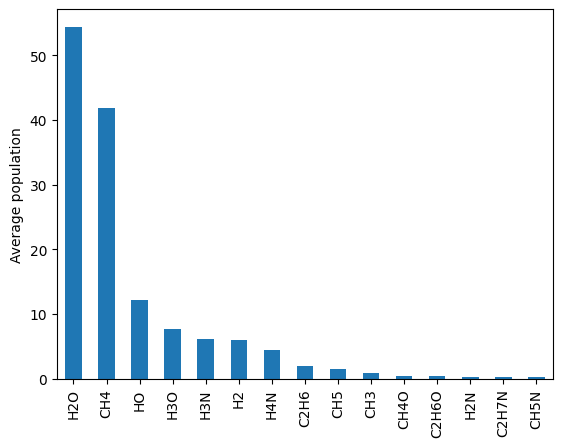

In [11]:
molecular_pops.mean()[1:].sort_values()[::-1][:15].plot.bar()
plt.ylabel('Average population')
plt.show()

##### Suppose we are only interested in molecules containing at least one N atom :

In [17]:
N_molecular_pops = molecular_pops.loc[:, molecular_pops.columns.str.contains('N')] # only keep molecules that contain N
N_molecular_pops = pd.concat([molecular_pops.iloc[:,[0]], N_molecular_pops], axis=1) # add the Step column (not necessary)

In [18]:
N_molecular_pops

,Step,H4N,H3N,H2N,CH6N,CH5N,CH4N,H5N,HN,CH7N,...,C2H6N,C2H5N,C2H8NO,C2H7NO,C2H6NO,C2H9NO,C2H9N,C2H5NO,C2H3NO,C2H4NO
0,0,9,3,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,7,5,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,2,7,5,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,3,8,4,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4,5,7,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
725,725,5,5,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
726,726,1,7,2,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
727,727,3,6,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
728,728,5,5,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


<Axes: >

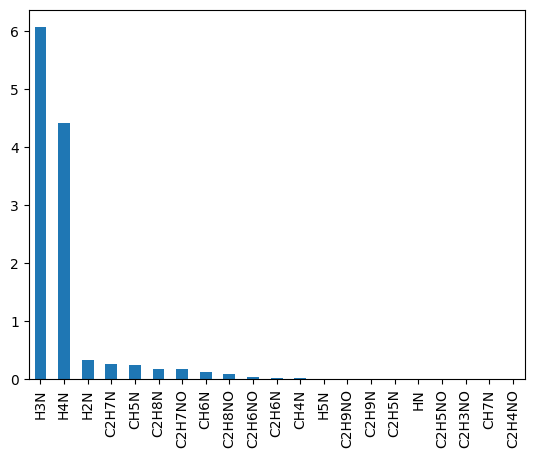

In [19]:
N_molecular_pops.mean()[1:].sort_values()[::-1].plot.bar()

#### 2.3. Studying a particular molecule

##### We can see there are **more complex molecules** like C2H7NO for which it may be useful to see the actual **topological formula**.

**To that end, we convert our `networkx` graphs into `rdkit` molecules and draw them**

Suppose we are interested in **$C_2H_7NO$** and its acid/base conjugates. First, let's **isolate the frames in which this family of molecules appear**. 

In [35]:
interesting_molecules = ['C2H6NO', 'C2H7NO', 'C2H8NO', 'C2H9NO', 'C2H5NO', 'C2H4NO', 'C2H3NO']
steps_with_intrstg_mols = {}
for mol in interesting_molecules:
    steps_with_intrstg_mols[mol] = molecular_pops[mol][molecular_pops[mol]>0].index.to_numpy()

In [36]:
# Number of timesteps in which the molecule appears
for mol in interesting_molecules:
    print(mol, len(steps_with_intrstg_mols[mol]))

C2H6NO 27
C2H7NO 124
C2H8NO 65
C2H9NO 7
C2H5NO 3
C2H4NO 1
C2H3NO 1


$C_2H_7NO$ is the most frequent molecule. This suggests that the neutral molecule only has single bonds. Let us check this, and learn more about the geometry of this molecule.

In [38]:
step_nbr = steps_with_intrstg_mols['C2H7NO'][0]
frame = analysis_result.frames[step_nbr]
atom_in_c2h7no = np.arange(frame.N_atom)[np.asarray(frame.get_molecule_formulas())=='C2H7NO'][0]
c2h7no_graph = frame.get_molecule_list()[atom_in_c2h7no]

##### The function `re.graph_to_rdkit(molecule_graph, labels_list)` converts a `networkx` molecular graph to an `rdkit Mol` object which can be drawn using `rdkit.Chem.Draw` methods. 

Its use is very simple, it takes two arguments:
- `graph`: the `networkx Graph` of the molecule you want to convert (typically you access it through `X.molecule` where `X` is a `Hydrogen` or `HeavyAtom`.
- `labels`: an array of labels, where `labels[i]` is the label of atom `i`. Typically it corresponds to `Frame.labels` where `Frame` is the Frame-object atom `X` belongs to.

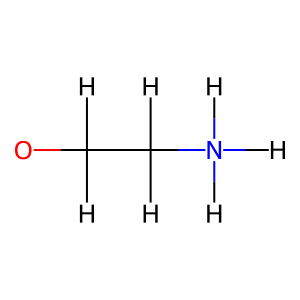

In [40]:
rdkit_mol = re.graph_to_rdkit(c2h7no_graph, frame.labels)
Draw.MolToImage(rdkit_mol)

##### Are there any isomers of this molecule ? What are their relative proportions ?

In [41]:
from rdkit.Chem import inchi
# inchi is a unique identifier for the chemistry of a molecule (geometry, charges, bond types).

isomers_occurences = {}
isomers_molecules = []

for ts in steps_with_intrstg_mols['C2H7NO']:
    frame = analysis_result.frames[ts]
    mols_list = frame.get_molecule_list()
    mols_formulas = np.asarray(frame.get_molecule_formulas())
    unique_exemplaries = list(set([mol for mol, keep in zip(mols_list, mols_formulas=='C2H7NO') if keep]))

    for mol in unique_exemplaries:
        rdkit_mol = re.graph_to_rdkit(mol, frame.labels)
        mol_inchi = inchi.MolToInchi(rdkit_mol)
        if mol_inchi not in isomers_occurences.keys():
            isomers_occurences[mol_inchi] = [ts] 
            isomers_molecules.append(rdkit_mol)
        else:
            isomers_occurences[mol_inchi].append(ts)

In [42]:
print(f'There are {len(list(isomers_occurences.keys()))} isomers of C2H7NO :')

There are 3 isomers of C2H7NO :


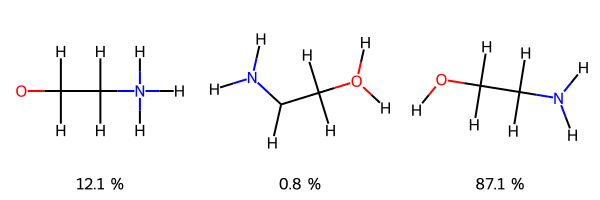

In [43]:
# Count the number of occurences of each inchi then divide by total number 
relative_abundance = np.asarray([len(x) for x in isomers_occurences.values()], dtype=float)
relative_abundance /= relative_abundance.sum()
legend = [f"{x*100:.1f} %" for x in relative_abundance]
# Draw each isomer with its abundance as a label
Draw.MolsToGridImage(isomers_molecules, molsPerRow=3, subImgSize=(200,200), legends=legend)

## END for now

#### Now let's look at the relative abundances of the acid and base that are conjugate to the predominant isomer of $C_2H_7NO$

First, we want to identify the corresponding inchi's.

In [97]:
from rdkit.Chem import inchi
# inchi is a unique identifier for the chemistry of a molecule (geometry, charges, bond types).

isomers_occurences = []
isomers_molecules = []

for i, mol_form in enumerate(['C2H6NO', 'C2H7NO', 'C2H8NO']):
    isomers_occurences.append({})
    isomers_molecules.append([])
    for ts in steps_with_intrstg_mols[mol_form]:
        frame = analysis_result.frames[ts]
        mols_list = frame.get_molecule_list()
        mols_formulas = np.asarray(frame.get_molecule_formulas())
        unique_exemplaries = list(set([mol for mol, keep in zip(mols_list, mols_formulas==mol_form) if keep]))
    
        for mol in unique_exemplaries:
            rdkit_mol = re.graph_to_rdkit(mol, frame.labels)
            mol_inchi = inchi.MolToInchi(rdkit_mol)
            if mol_inchi not in isomers_occurences[i].keys():
                isomers_occurences[i][mol_inchi] = [ts] 
                isomers_molecules[i].append(rdkit_mol)
            else:
                isomers_occurences[i][mol_inchi].append(ts)

In [106]:
print([len(x) for x in isomers_molecules])

[3, 3, 3]


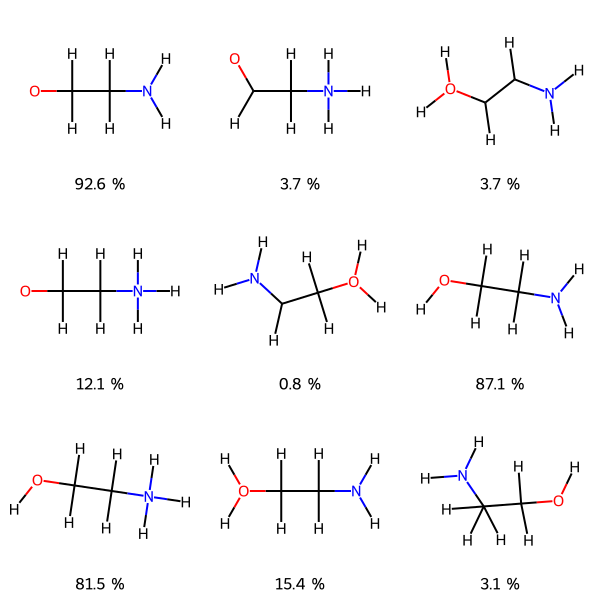

In [108]:
# Count the number of occurences of each inchi then divide by total number 
relative_abundance = []
legend = []
for i, mol_form in enumerate(['C2H6NO', 'C2H7NO', 'C2H8NO']):
    relative_abundance.append(np.asarray([len(x) for x in isomers_occurences[i].values()], dtype=float))
    relative_abundance[-1] /= relative_abundance[-1].sum()
    legend.append([f"{x*100:.1f} %" for x in relative_abundance[-1]])
# Draw each isomer with its abundance as a label
Draw.MolsMatrixToGridImage(isomers_molecules, subImgSize=(200,200), legendsMatrix=legend)

In [114]:
conjugates = [[True, False, False],
              [True, False, True],
              [True, False, False]]

In [122]:
keys_arr[conjugates]

array(['InChI=1S/C2H7NO/c3-1-2-4/h4H,1-3H2',
       'InChI=1S/C2H8NO/c3-1-2-4/h4H,1-2H2,3H3',
       'InChI=1S/C2H7NO/c3-1-2-4/h4H,1-3H2',
       'InChI=1S/C2H8NO/c3-1-2-4/h4H,1-2H2,3H3'], dtype='<U38')

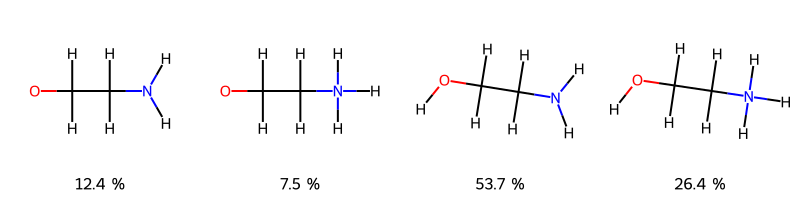

In [130]:
# Count the number of occurences of each inchi then divide by total number 
relative_abundance = []
keys_arr = np.asarray([list(isom.keys()) for isom in isomers_occurences])
for ind, key in zip(np.nonzero(conjugates)[0], keys_arr[conjugates]):
    relative_abundance.append(len(isomers_occurences[ind][key]))
relative_abundance = np.asarray(relative_abundance, dtype=float)
relative_abundance /= relative_abundance.sum()
legend = [f"{x*100:.1f} %" for x in relative_abundance]
# Draw each isomer with its abundance as a label
Draw.MolsToGridImage(np.asarray(isomers_molecules)[conjugates], molsPerRow=4, subImgSize=(200,200), legends=legend)